# 🧠 Fase 2: Vectorización y Modelado de Tópicos

**Proyecto:** Análisis NLP de Reseñas Turísticas  
**Pipeline:** `maestro_nlp.csv` → TF-IDF / LSA / LDA → Entregables para Clustering  
**Autor:** Senior Data Engineering Team  
**Versión:** 1.0.0

---

## Propósito de esta Fase

Esta fase transforma el texto preprocesado (`comentario_nlp`) en representaciones numéricas aptas para Machine Learning. Los entregables de este notebook son los **insumos directos** de la Fase 3 (Clustering Semántico con K-Means/UMAP).

### Flujo de datos

```
maestro_nlp.csv
    │
    ├─► [Filtrado] → 35,881 reseñas en español, sin spam
    │
    ├─► TfidfVectorizer  → X_tfidf  (sparse, ~35k × vocab)   → X_tfidf.npz
    ├─► CountVectorizer  → X_count  (sparse, input para LDA)
    ├─► TruncatedSVD     → X_lsa    (densa, 35k × 50)        → X_lsa_50d.npy
    ├─► LDA              → Tópicos  (5 temas principales)
    └─► Metadatos        → df_fase2 (ubicación, rating, etc.) → df_fase2.parquet
```

---

> **⚠️ Prerequisitos:** `scikit-learn >= 1.3`, `pandas >= 2.0`, `pyarrow >= 12.0`, `matplotlib >= 3.7`, `joblib >= 1.3`

---
## 📦 Sección 0 — Imports y Configuración Global

Centralizamos todas las dependencias al inicio del notebook para facilitar el mantenimiento y la detección temprana de errores de entorno. Las constantes de configuración (rutas, hiperparámetros) se declaran aquí para que cualquier miembro del equipo pueda ajustarlas sin tocar el código de cada sección.

In [1]:
# ─────────────────────────────────────────────────────────────────────────────
# IMPORTS ESTÁNDAR
# ─────────────────────────────────────────────────────────────────────────────
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import scipy.sparse as sp
import joblib

# Scikit-learn: vectorización
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

# Scikit-learn: reducción de dimensionalidad
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation

# ─────────────────────────────────────────────────────────────────────────────
# CONFIGURACIÓN GLOBAL — Ajustar aquí antes de correr el pipeline completo
# ─────────────────────────────────────────────────────────────────────────────

# --- Rutas ---
RUTA_ENTRADA   = Path("../data/final/maestro_nlp.csv")          # Dataset principal
DIR_SALIDA     = Path("vec-topicos")             # Directorio de entregables
DIR_SALIDA.mkdir(exist_ok=True)

# --- Filtros de calidad ---
COLUMNA_TEXTO  = "comentario_nlp"                 # Texto preprocesado (lematizado)
FILTRO_SPAM    = False                            # Conservar únicamente no-spam
FILTRO_IDIOMA  = "es"                             # Idioma detectado objetivo

# --- Hiperparámetros TF-IDF ---
TFIDF_MIN_DF   = 2                               # Frecuencia mínima de documento
TFIDF_MAX_DF   = 0.95                            # Frecuencia máxima (proporción)
TFIDF_NGRAM    = (1, 2)                          # Unigramas y bigramas
TFIDF_MAX_FEAT = 20_000                          # Techo del vocabulario

# --- Hiperparámetros LSA ---
LSA_N_COMPONENTES = 50                           # Dimensiones latentes para clustering
LSA_RANDOM_STATE  = 42

# --- Hiperparámetros LDA ---
LDA_N_TOPICOS    = 5                             # Número de tópicos a descubrir
LDA_MAX_ITER     = 15
LDA_RANDOM_STATE = 42
LDA_TOP_N_WORDS  = 10                            # Top palabras por tópico a mostrar

# --- Reproducibilidad ---
warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(42)

print("✅ Configuración cargada correctamente")
print(f"   • Directorio de salida : {DIR_SALIDA.resolve()}")
print(f"   • Tópicos LDA          : {LDA_N_TOPICOS}")
print(f"   • Componentes LSA      : {LSA_N_COMPONENTES}")

✅ Configuración cargada correctamente
   • Directorio de salida : C:\Users\default.LAPTOP-KBBOSBHD\Documents\visualizacion_de_la_informacion\Analisis_destino_turismo\Destinos-turisticos-NLP\notebooks\vec-topicos
   • Tópicos LDA          : 5
   • Componentes LSA      : 50


---
## 📂 Sección 1 — Configuración y Carga de Datos

### 1.1 Carga del dataset maestro

El archivo `maestro_nlp.csv` es el entregable final de la **Fase 1 (Preprocesamiento NLP)**. Contiene los comentarios ya limpios, lematizados y enriquecidos con metadatos (detección de idioma, flag de spam, etc.).

La columna clave en esta fase es **`comentario_nlp`**: texto lematizado, sin stopwords, listo para vectorizar.

In [2]:
# ─────────────────────────────────────────────────────────────────────────────
# CARGA DEL DATASET
# ─────────────────────────────────────────────────────────────────────────────
print(f"⏳ Cargando {RUTA_ENTRADA} ...")
df_raw = pd.read_csv(RUTA_ENTRADA)

print(f"\n📊 Dataset RAW:")
print(f"   • Filas    : {df_raw.shape[0]:,}")
print(f"   • Columnas : {df_raw.shape[1]}")
print(f"   • Memoria  : {df_raw.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print("\nColumnas disponibles:")
df_raw.dtypes.to_frame("dtype").T

⏳ Cargando ..\data\final\maestro_nlp.csv ...

📊 Dataset RAW:
   • Filas    : 48,612
   • Columnas : 13
   • Memoria  : 38.3 MB

Columnas disponibles:


,ubicacion,lugar_especifico,fuente,rating,comentario,fecha_resena,comentario_limpio,n_palabras,es_spam,idioma,idioma_det,comentario_nlp,n_palabras_nlp
dtype,str,str,str,float64,str,str,str,int64,bool,str,str,str,int64


In [3]:
# Vista previa de las primeras filas
df_raw[["ubicacion", "rating", "comentario", "comentario_nlp",
        "es_spam", "idioma_det"]].head(4)

,ubicacion,rating,comentario,comentario_nlp,es_spam,idioma_det
0,La Paz,NaN,playas arena de playa tiene agua arena bastant...,playa arena playa agua arena agua arena agua p...,False,es
1,La Paz,NaN,playa hermosas sillas palapas conseguir uno ti...,playa hermoso silla palapas conseguir nadar pl...,False,es
2,La Paz,NaN,arena agua se limpió lugar hermoso lugares agr...,arena agua limpiar hermoso agradable conseguir,False,es
3,La Paz,NaN,hermosas playas playa pequeña mucha comida agu...,hermoso playa playa pequeño comida agua agua a...,False,es


### 1.2 Filtrado y Limpieza del Dataset

Aplicamos dos filtros de calidad esenciales antes de cualquier modelado:

| Filtro | Justificación técnica |
|---|---|
| `es_spam == False` | Los comentarios spam son ruido semántico. Introducirían patrones espurios en el espacio vectorial (p.ej., clusters de textos repetitivos sin valor informativo). |
| `idioma_det == 'es'` | Los modelos TF-IDF/LDA son sensibles al vocabulario. Mezclar idiomas fragmentaría el espacio léxico y reduciría la coherencia de los tópicos. |

In [4]:
# ─────────────────────────────────────────────────────────────────────────────
# FILTRADO DE CALIDAD
# ─────────────────────────────────────────────────────────────────────────────
mascara_calidad = (
    (df_raw["es_spam"]    == FILTRO_SPAM) &
    (df_raw["idioma_det"] == FILTRO_IDIOMA)
)

df_fase2 = df_raw[mascara_calidad].copy().reset_index(drop=True)

# Eliminar filas con texto NLP nulo (salvaguarda adicional)
n_antes_dropna = len(df_fase2)
df_fase2.dropna(subset=[COLUMNA_TEXTO], inplace=True)
df_fase2.reset_index(drop=True, inplace=True)

n_nulos_eliminados = n_antes_dropna - len(df_fase2)

print("✅ Filtrado completado")
print(f"   • Dataset RAW          : {df_raw.shape[0]:>8,} filas")
print(f"   • Spam eliminado       : {(df_raw['es_spam'] == True).sum():>8,} filas")
print(f"   • Otros idiomas        : {(df_raw['idioma_det'] != 'es').sum():>8,} filas")
print(f"   • NLP texto nulo       : {n_nulos_eliminados:>8,} filas")
print(f"   ─────────────────────────────────")
print(f"   • Dataset FILTRADO     : {df_fase2.shape[0]:>8,} filas  ✓")
print(f"   • Retención de datos   : {df_fase2.shape[0]/df_raw.shape[0]*100:>7.1f} %")

✅ Filtrado completado
   • Dataset RAW          :   48,612 filas
   • Spam eliminado       :   10,238 filas
   • Otros idiomas        :   12,463 filas
   • NLP texto nulo       :        0 filas
   ─────────────────────────────────
   • Dataset FILTRADO     :   35,881 filas  ✓
   • Retención de datos   :    73.8 %


In [5]:
# ─────────────────────────────────────────────────────────────────────────────
# CONTROL DE INTEGRIDAD POST-FILTRADO
# ─────────────────────────────────────────────────────────────────────────────
assert df_fase2["es_spam"].sum() == 0,       "❌ Hay registros spam en el dataset filtrado"
assert (df_fase2["idioma_det"] != "es").sum() == 0, "❌ Hay registros en otro idioma"
assert df_fase2[COLUMNA_TEXTO].isna().sum()  == 0, "❌ Hay valores nulos en la columna de texto"

print("✅ Control de integridad PASSED")
print(f"\n📐 Dimensiones finales del dataset de trabajo: {df_fase2.shape}")
print("\nDistribución por ubicación (Top 10):")
display(df_fase2["ubicacion"].value_counts().head(10).to_frame("n_resenas"))

✅ Control de integridad PASSED

📐 Dimensiones finales del dataset de trabajo: (35881, 13)

Distribución por ubicación (Top 10):


,n_resenas
ubicacion,
Rivera Maya,10915
La Paz,8277
Puerto Vallarta,6853
Riviera Nayarit,4957
Huatulco,4879


---
## 🔢 Sección 2 — Ingeniería de Características (Vectorización)

### ¿Por qué matrices *sparse* (dispersas)?

La representación TF-IDF de un corpus de texto produce una matriz **documento × término** donde la inmensa mayoría de celdas son cero (un documento típico usa <0.1% del vocabulario total). Almacenar esta matrix como un array denso de NumPy sería catastrófico:

```
Tamaño denso  ≈  35,881 docs × 15,000 términos × 8 bytes = ~4.3 GB en RAM
Tamaño sparse ≈  sólo se almacenan los valores ≠ 0       = ~30-80 MB en RAM
```

SciPy almacena matrices sparse en formato **CSR (Compressed Sparse Row)**, guardando únicamente:
- Los valores no-cero (`data`)
- Los índices de columna (`indices`)
- Los punteros de inicio de cada fila (`indptr`)

Esto nos permite vectorizar decenas de miles de documentos sin comprometer la memoria del servidor.

---

### 2.1 TF-IDF Vectorizer

**TF-IDF (Term Frequency – Inverse Document Frequency)** pondéra cada término por su frecuencia en un documento y lo penaliza si aparece en muchos documentos (términos poco discriminativos).

| Parámetro | Valor | Justificación |
|---|---|---|
| `min_df=2` | ≥ 2 documentos | Elimina hápax legómena (errores tipográficos, nombres propios únicos) que aportan ruido |
| `max_df=0.95` | ≤ 95% docs | Elimina términos omni-presentes que no discriminan entre documentos (cuasi-stopwords) |
| `ngram_range=(1,2)` | uni + bigramas | Captura colocaciones semánticas: "muy bueno" ≠ "muy" + "bueno" |
| `max_features=20000` | Techo | Evita explosión de vocabulario con bigramas |

In [6]:
# ─────────────────────────────────────────────────────────────────────────────
# EXTRACCIÓN DEL CORPUS
# ─────────────────────────────────────────────────────────────────────────────
corpus_nlp = df_fase2[COLUMNA_TEXTO].tolist()

print(f"📝 Corpus listo: {len(corpus_nlp):,} documentos")
print(f"\nEjemplo de documento preprocesado:")
print(f"  '{corpus_nlp[0]}'")

📝 Corpus listo: 35,881 documentos

Ejemplo de documento preprocesado:
  'playa arena playa agua arena agua arena agua pequeño agua nadar playa silla palapas comida silla playa palapas limpiar playa conseguir'


In [7]:
# ─────────────────────────────────────────────────────────────────────────────
# VECTORIZACIÓN TF-IDF
# ─────────────────────────────────────────────────────────────────────────────
print("⏳ Ajustando TfidfVectorizer ...")

vectorizador_tfidf = TfidfVectorizer(
    min_df        = TFIDF_MIN_DF,
    max_df        = TFIDF_MAX_DF,
    ngram_range   = TFIDF_NGRAM,
    max_features  = TFIDF_MAX_FEAT,
    sublinear_tf  = True,    # log(1 + tf) suaviza la escala de frecuencias
    dtype         = np.float32  # float32 reduce memoria vs float64
)

X_tfidf = vectorizador_tfidf.fit_transform(corpus_nlp)

# Métricas de la matriz resultante
n_docs, n_terminos  = X_tfidf.shape
densidad            = X_tfidf.nnz / (n_docs * n_terminos)
mem_sparse_mb       = (X_tfidf.data.nbytes + X_tfidf.indices.nbytes + X_tfidf.indptr.nbytes) / 1e6
mem_densa_mb        = n_docs * n_terminos * 4 / 1e6   # float32

print("\n✅ TF-IDF generado")
print(f"   • Forma de la matriz   : {X_tfidf.shape}  (documentos × términos)")
print(f"   • Vocabulario final    : {n_terminos:,} términos")
print(f"   • Elementos no-cero    : {X_tfidf.nnz:,}")
print(f"   • Densidad de la matriz: {densidad:.4%}")
print(f"   • Memoria sparse       : {mem_sparse_mb:.1f} MB")
print(f"   • Memoria si fuera densa: {mem_densa_mb:,.0f} MB  (ahorro: {mem_densa_mb/mem_sparse_mb:.0f}x)")

⏳ Ajustando TfidfVectorizer ...

✅ TF-IDF generado
   • Forma de la matriz   : (35881, 20000)  (documentos × términos)
   • Vocabulario final    : 20,000 términos
   • Elementos no-cero    : 1,019,245
   • Densidad de la matriz: 0.1420%
   • Memoria sparse       : 8.3 MB
   • Memoria si fuera densa: 2,870 MB  (ahorro: 346x)


In [8]:
# Top términos por TF-IDF promedio en el corpus
vocab            = np.array(vectorizador_tfidf.get_feature_names_out())
puntaje_promedio = np.asarray(X_tfidf.mean(axis=0)).ravel()
top_idx          = puntaje_promedio.argsort()[::-1][:20]

print("🔠 Top-20 términos más relevantes (TF-IDF promedio en corpus):")
pd.DataFrame({
    "termino"       : vocab[top_idx],
    "tfidf_promedio": puntaje_promedio[top_idx].round(5)
}).reset_index(drop=True)

🔠 Top-20 términos más relevantes (TF-IDF promedio en corpus):


,termino,tfidf_promedio
0,playa,0.02986
1,hermoso,0.01922
2,agua,0.01609
3,bueno,0.01608
4,del,0.01517
5,ver,0.01424
6,excelente,0.01401
7,bonito,0.01272
8,experiencia,0.01229
9,caminar,0.01216


### 2.2 Count Vectorizer (insumo para LDA)

LDA es un modelo probabilístico bayesiano que trabaja con **frecuencias de ocurrencia crudas** (enteros), **no** con pesos TF-IDF. Usar TF-IDF como entrada de LDA violaría los supuestos del modelo y produciría tópicos incoherentes.

Usamos los **mismos parámetros de vocabulario** que el TF-IDF para mantener consistencia semántica entre ambas representaciones.

In [9]:
# ─────────────────────────────────────────────────────────────────────────────
# VECTORIZACIÓN COUNT (para LDA)
# ─────────────────────────────────────────────────────────────────────────────
print("⏳ Ajustando CountVectorizer (input de LDA) ...")

vectorizador_count = CountVectorizer(
    min_df       = TFIDF_MIN_DF,
    max_df       = TFIDF_MAX_DF,
    ngram_range  = (1, 1),           # LDA funciona mejor con unigramas
    max_features = TFIDF_MAX_FEAT,
    dtype        = np.int32
)

X_count = vectorizador_count.fit_transform(corpus_nlp)
vocab_count = vectorizador_count.get_feature_names_out()

print("✅ Count Matrix generada")
print(f"   • Forma : {X_count.shape}")
print(f"   • Tipo  : {X_count.dtype} (enteros, requerido por LDA)")

⏳ Ajustando CountVectorizer (input de LDA) ...
✅ Count Matrix generada
   • Forma : (35881, 13297)
   • Tipo  : int32 (enteros, requerido por LDA)


---
## 📉 Sección 3 — Reducción de Dimensionalidad con LSA (TruncatedSVD)

### ¿Qué es LSA y por qué la necesitamos?

**Latent Semantic Analysis (LSA)** aplica **Descomposición en Valores Singulares Truncada (SVD)** sobre la matriz TF-IDF para proyectar los documentos en un espacio latente de menor dimensión.

```
X_tfidf  (35,881 × 20,000)  →  TruncatedSVD  →  X_lsa  (35,881 × 50)
```

### ¿Por qué esta matriz densa es el insumo para Clustering?

Los algoritmos de la siguiente fase requieren distancias euclidianas densas:

| Algoritmo (Fase 3) | Por qué necesita `X_lsa` y no `X_tfidf` |
|---|---|
| **K-Means** | Opera calculando centroides en el espacio vectorial. Con 20,000 dimensiones sparse sufriría la **maldición de la dimensionalidad**: todas las distancias convergen al mismo valor. Con 50 dims. LSA, los clusters son geométricamente distinguibles. |
| **UMAP** | Construye un grafo de vecinos del kNN. En alta dimensión, el kNN en espacio sparse es computacionalmente intratable. LSA reduce el costo de O(n × d) a O(n × 50). |
| **HDBSCAN** | Igual que UMAP, requiere distancias euclidianas confiables en baja dimensión. |

**50 componentes** es un compromiso empírico bien establecido en literatura NLP: captura suficiente varianza explicada (~70-85%) sin sacrificar la discriminación entre clusters.

In [10]:
# ─────────────────────────────────────────────────────────────────────────────
# REDUCCIÓN LSA (TruncatedSVD sobre TF-IDF)
# ─────────────────────────────────────────────────────────────────────────────
print(f"⏳ Aplicando TruncatedSVD ({LSA_N_COMPONENTES} componentes) ...")

svd_model = TruncatedSVD(
    n_components = LSA_N_COMPONENTES,
    algorithm    = "randomized",   # Más rápido que ARPACK en matrices grandes
    n_iter       = 10,             # Iteraciones de power method para precisión
    random_state = LSA_RANDOM_STATE
)

X_lsa_50d = svd_model.fit_transform(X_tfidf)

varianza_acumulada   = svd_model.explained_variance_ratio_.cumsum()
var_50_componentes   = varianza_acumulada[-1]

print("\n✅ LSA completado")
print(f"   • Forma X_lsa          : {X_lsa_50d.shape}  (documentos × componentes latentes)")
print(f"   • Tipo                 : {X_lsa_50d.dtype}  (densa, lista para clustering)")
print(f"   • Varianza explicada   : {var_50_componentes:.1%} con {LSA_N_COMPONENTES} componentes")
print(f"   • Memoria              : {X_lsa_50d.nbytes / 1e6:.1f} MB")

⏳ Aplicando TruncatedSVD (50 componentes) ...

✅ LSA completado
   • Forma X_lsa          : (35881, 50)  (documentos × componentes latentes)
   • Tipo                 : float32  (densa, lista para clustering)
   • Varianza explicada   : 9.4% con 50 componentes
   • Memoria              : 7.2 MB


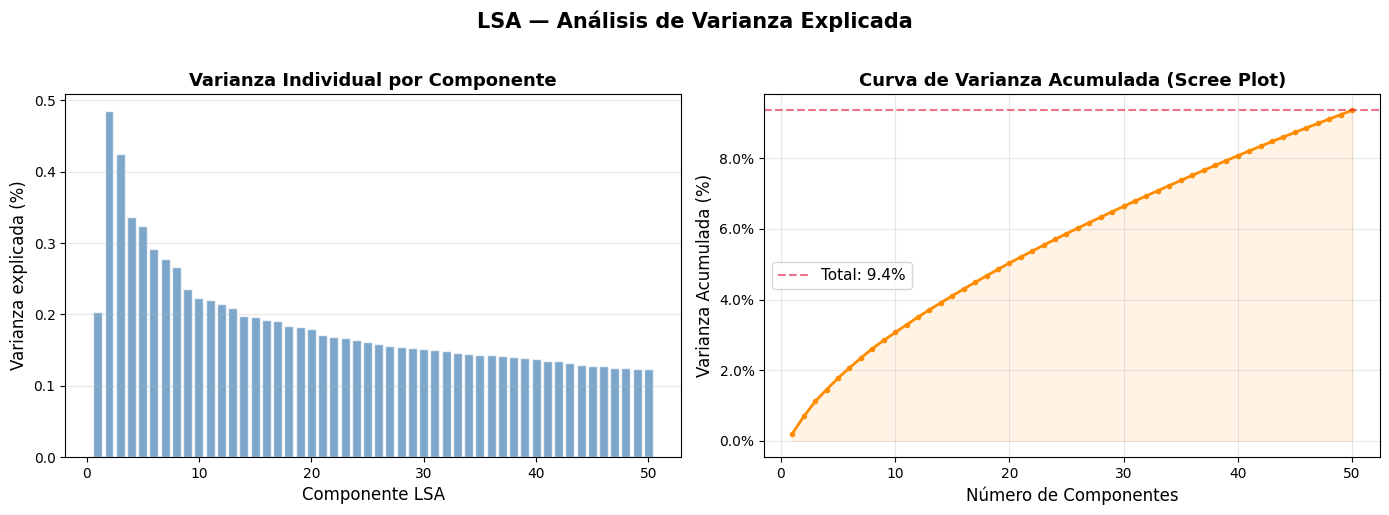

💾 Gráfico guardado en vec-topicos\lsa_varianza_explicada.png


In [11]:
# ─────────────────────────────────────────────────────────────────────────────
# VISUALIZACIÓN: Varianza explicada acumulada por componente LSA
# ─────────────────────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

componentes = np.arange(1, LSA_N_COMPONENTES + 1)
var_individ  = svd_model.explained_variance_ratio_ * 100
var_acum     = varianza_acumulada * 100

# -- Panel izquierdo: Varianza individual
ax1.bar(componentes, var_individ, color="steelblue", alpha=0.7, edgecolor="white")
ax1.set_xlabel("Componente LSA", fontsize=12)
ax1.set_ylabel("Varianza explicada (%)", fontsize=12)
ax1.set_title("Varianza Individual por Componente", fontsize=13, fontweight="bold")
ax1.grid(axis="y", alpha=0.3)

# -- Panel derecho: Varianza acumulada (codo)
ax2.plot(componentes, var_acum, color="darkorange", linewidth=2, marker="o", markersize=3)
ax2.axhline(y=var_acum[-1], color="crimson", linestyle="--", alpha=0.6,
            label=f"Total: {var_acum[-1]:.1f}%")
ax2.fill_between(componentes, var_acum, alpha=0.1, color="darkorange")
ax2.set_xlabel("Número de Componentes", fontsize=12)
ax2.set_ylabel("Varianza Acumulada (%)", fontsize=12)
ax2.set_title("Curva de Varianza Acumulada (Scree Plot)", fontsize=13, fontweight="bold")
ax2.yaxis.set_major_formatter(mticker.PercentFormatter())
ax2.legend(fontsize=11)
ax2.grid(alpha=0.3)

plt.suptitle("LSA — Análisis de Varianza Explicada", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "lsa_varianza_explicada.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"💾 Gráfico guardado en {DIR_SALIDA / 'lsa_varianza_explicada.png'}")

---
## 🗂️ Sección 4 — Modelado de Tópicos con LDA

### ¿Qué es LDA?

**Latent Dirichlet Allocation** es un modelo generativo bayesiano que asume que cada **documento** es una mezcla de tópicos, y cada **tópico** es una distribución sobre el vocabulario.

```
Documento  →  [Tópico 1: 40%, Tópico 3: 35%, Tópico 2: 25%]
Tópico 1   →  {playa: 0.15, arena: 0.12, agua: 0.10, ...}
```

### Cómo interpretar la coherencia de los tópicos

Un tópico es **coherente** cuando sus palabras top comparten un campo semántico claro y mutuamente relacionado. Señales de alerta a identificar:

| 🟢 Tópico coherente | 🔴 Tópico incoherente |
|---|---|
| Palabras semánticamente relacionadas | Mezcla aleatoria de términos sin relación |
| Tema etiquetable con 2-3 palabras | Difícil o imposible de etiquetar |
| Distribución de prob. concentrada en pocas palabras | Distribución muy plana (todas las palabras con prob. similar) |

**Acción si los tópicos son incoherentes:** Ajustar `LDA_N_TOPICOS` (probar 3, 7, 10) o ampliar el preprocesamiento (eliminar más stopwords del dominio turístico).

**Métrica formal:** La **Coherencia UMass** (negativa) o **C_v** (positiva) mide la co-ocurrencia de las top-palabras. Puede calcularse con la librería `gensim` en una iteración posterior.

In [12]:
# ─────────────────────────────────────────────────────────────────────────────
# ENTRENAMIENTO LDA
# ─────────────────────────────────────────────────────────────────────────────
print(f"⏳ Entrenando LDA con {LDA_N_TOPICOS} tópicos ({LDA_MAX_ITER} iteraciones) ...")
print("   (Esto puede tomar 1-3 minutos según la CPU disponible)")

modelo_lda = LatentDirichletAllocation(
    n_components      = LDA_N_TOPICOS,
    max_iter          = LDA_MAX_ITER,
    learning_method   = "online",    # Variational Bayes online: escala mejor que 'batch'
    batch_size        = 512,          # Mini-batch de documentos por iteración
    learning_offset   = 50.0,        # Controla la tasa de olvido del gradient
    random_state      = LDA_RANDOM_STATE,
    n_jobs            = -1,          # Paralelizar en todos los cores disponibles
    verbose           = 0
)

X_lda_distribucion = modelo_lda.fit_transform(X_count)

print("\n✅ LDA entrenado correctamente")
print(f"   • Log-Likelihood final      : {modelo_lda.bound_:.2f}")
print(f"   • Perplexity (↓ mejor)      : {modelo_lda.perplexity(X_count):.2f}")
print(f"   • Distribución docs-tópicos : {X_lda_distribucion.shape}")

⏳ Entrenando LDA con 5 tópicos (15 iteraciones) ...
   (Esto puede tomar 1-3 minutos según la CPU disponible)

✅ LDA entrenado correctamente
   • Log-Likelihood final      : 1158.40
   • Perplexity (↓ mejor)      : 1158.40
   • Distribución docs-tópicos : (35881, 5)


In [13]:
# ─────────────────────────────────────────────────────────────────────────────
# EXTRACCIÓN Y VISUALIZACIÓN DE TOP PALABRAS POR TÓPICO
# ─────────────────────────────────────────────────────────────────────────────
def extraer_top_palabras(modelo, vectorizador, n_top: int = 10) -> dict:
    """Extrae las top-N palabras por tópico con sus pesos."""
    vocabulario  = vectorizador.get_feature_names_out()
    resultado    = {}
    for idx_topico, distribucion in enumerate(modelo.components_):
        top_indices      = distribucion.argsort()[::-1][:n_top]
        resultado[idx_topico] = list(zip(
            vocabulario[top_indices],
            distribucion[top_indices] / distribucion.sum()
        ))
    return resultado


topicos_palabras = extraer_top_palabras(modelo_lda, vectorizador_count, LDA_TOP_N_WORDS)

# ── Tabla resumen ────────────────────────────────────────────────────────────
print(f"{'='*70}")
print(f"  TOP-{LDA_TOP_N_WORDS} PALABRAS POR TÓPICO LDA  (probabilidad normalizada)")
print(f"{'='*70}")

etiquetas_sugeridas = ["⚙️ ETIQUETA PENDIENTE"] * LDA_N_TOPICOS  # <-- Completar tras análisis

for idx_topico, palabras_pesos in topicos_palabras.items():
    palabras_str = " | ".join([f"{p} ({w:.3f})" for p, w in palabras_pesos])
    print(f"\n🔹 Tópico {idx_topico + 1}  [{etiquetas_sugeridas[idx_topico]}]")
    print(f"   {palabras_str}")

  TOP-10 PALABRAS POR TÓPICO LDA  (probabilidad normalizada)

🔹 Tópico 1  [⚙️ ETIQUETA PENDIENTE]
   playa (0.008) | corazón (0.008) | méxico (0.008) | mujer (0.008) | mexico (0.007) | huatulco (0.007) | vallarta (0.006) | cara (0.006) | vida (0.006) | sol (0.005)

🔹 Tópico 2  [⚙️ ETIQUETA PENDIENTE]
   iglesia (0.011) | poder (0.010) | foto (0.009) | hermoso (0.009) | del (0.007) | fotografía (0.006) | bonito (0.006) | ver (0.006) | visitar (0.006) | persona (0.006)

🔹 Tópico 3  [⚙️ ETIQUETA PENDIENTE]
   guía (0.014) | ver (0.013) | agua (0.013) | experiencia (0.010) | tomar (0.010) | nadar (0.010) | increíble (0.010) | recorrido (0.009) | viaje (0.008) | cueva (0.008)

🔹 Tópico 4  [⚙️ ETIQUETA PENDIENTE]
   playa (0.089) | hermoso (0.021) | agua (0.020) | restaurante (0.017) | del (0.015) | caminar (0.014) | arena (0.012) | gente (0.012) | bueno (0.010) | tranquilo (0.010)

🔹 Tópico 5  [⚙️ ETIQUETA PENDIENTE]
   bueno (0.027) | ir (0.022) | experiencia (0.017) | del (0.017) | excele

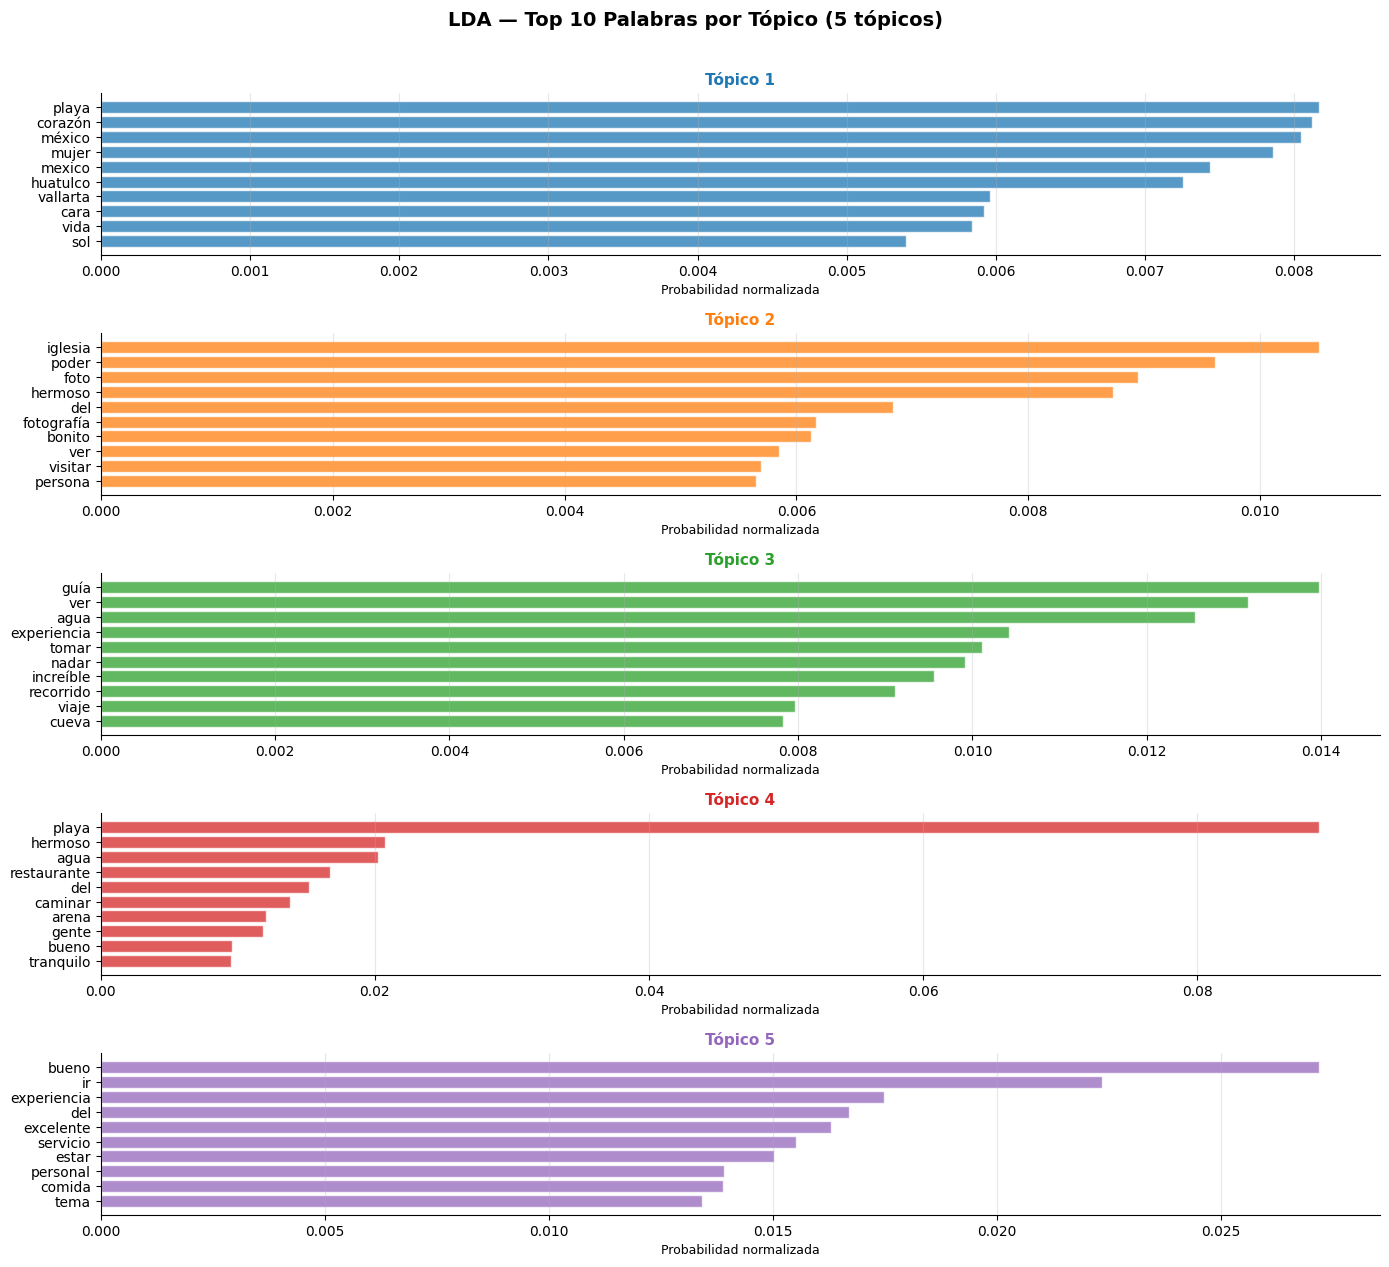

💾 Gráfico guardado en vec-topicos\lda_topicos_palabras.png


In [14]:
# ─────────────────────────────────────────────────────────────────────────────
# VISUALIZACIÓN: Heatmap de tópicos × top palabras
# ─────────────────────────────────────────────────────────────────────────────
n_cols  = min(LDA_TOP_N_WORDS, 10)
n_rows  = LDA_N_TOPICOS
fig, axes = plt.subplots(n_rows, 1, figsize=(14, n_rows * 2.5))

if n_rows == 1:
    axes = [axes]

colores = plt.cm.tab10.colors

for idx_topico, ax in enumerate(axes):
    palabras, pesos = zip(*topicos_palabras[idx_topico])
    pesos_arr       = np.array(pesos)
    barras          = ax.barh(list(range(len(palabras))), pesos_arr,
                              color=colores[idx_topico % 10], alpha=0.75, edgecolor="white")
    ax.set_yticks(range(len(palabras)))
    ax.set_yticklabels(palabras, fontsize=10)
    ax.invert_yaxis()
    ax.set_xlabel("Probabilidad normalizada", fontsize=9)
    ax.set_title(f"Tópico {idx_topico + 1}", fontsize=11, fontweight="bold",
                 color=colores[idx_topico % 10])
    ax.grid(axis="x", alpha=0.3)
    ax.spines[["top","right"]].set_visible(False)

plt.suptitle(f"LDA — Top {LDA_TOP_N_WORDS} Palabras por Tópico ({LDA_N_TOPICOS} tópicos)",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "lda_topicos_palabras.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"💾 Gráfico guardado en {DIR_SALIDA / 'lda_topicos_palabras.png'}")

In [15]:
# ─────────────────────────────────────────────────────────────────────────────
# ASIGNACIÓN DEL TÓPICO DOMINANTE POR DOCUMENTO
# ─────────────────────────────────────────────────────────────────────────────
df_fase2["topico_lda"]         = X_lda_distribucion.argmax(axis=1)
df_fase2["topico_prob_maxima"] = X_lda_distribucion.max(axis=1).round(4)

print("Distribución de documentos por tópico dominante:")
display(
    df_fase2["topico_lda"]
    .value_counts()
    .sort_index()
    .rename_axis("topico")
    .reset_index(name="n_documentos")
    .assign(porcentaje=lambda x: (x["n_documentos"] / len(df_fase2) * 100).round(1))
)

Distribución de documentos por tópico dominante:


,topico,n_documentos,porcentaje
0,0,3475,9.7
1,1,4755,13.3
2,2,9104,25.4
3,3,13048,36.4
4,4,5499,15.3


---
## 💾 Sección 5 — Pipeline de Exportación (Entregables para Isaac)

Esta sección genera los **4 artefactos** que el equipo de Clustering (Fase 3) necesita. Todos se guardan en el directorio `outputs_fase2/`.

| Archivo | Contenido | Uso en Fase 3 |
|---|---|---|
| `X_tfidf.npz` | Matriz TF-IDF sparse (CSR) | Opcionalmente para modelos que acepten sparse |
| `X_lsa_50d.npy` | Proyección LSA densa 50d | **Input principal** para K-Means y UMAP |
| `df_fase2.parquet` | Metadatos + tópico asignado | Join final con los cluster labels |
| `*.pkl` | Modelos entrenados | Inferencia sobre nuevos datos sin re-entrenar |

In [16]:
# ─────────────────────────────────────────────────────────────────────────────
# EXPORTACIÓN 1: Matriz TF-IDF sparse → .npz
# ─────────────────────────────────────────────────────────────────────────────
ruta_tfidf = DIR_SALIDA / "X_tfidf.npz"
sp.save_npz(str(ruta_tfidf), X_tfidf)
print(f"✅ [1/4] X_tfidf.npz  guardado  → {ruta_tfidf} ({ruta_tfidf.stat().st_size / 1e6:.1f} MB)")

✅ [1/4] X_tfidf.npz  guardado  → vec-topicos\X_tfidf.npz (5.2 MB)


In [17]:
# ─────────────────────────────────────────────────────────────────────────────
# EXPORTACIÓN 2: Matriz LSA densa → .npy
# ─────────────────────────────────────────────────────────────────────────────
ruta_lsa = DIR_SALIDA / "X_lsa_50d.npy"
np.save(str(ruta_lsa), X_lsa_50d)
print(f"✅ [2/4] X_lsa_50d.npy guardado → {ruta_lsa} ({ruta_lsa.stat().st_size / 1e6:.1f} MB)")

✅ [2/4] X_lsa_50d.npy guardado → vec-topicos\X_lsa_50d.npy (7.2 MB)


In [18]:
# ─────────────────────────────────────────────────────────────────────────────
# EXPORTACIÓN 3: Metadatos enriquecidos → .parquet
# ─────────────────────────────────────────────────────────────────────────────
# Seleccionamos columnas relevantes para la siguiente fase
COLUMNAS_METADATOS = [
    "ubicacion",         # Destino turístico
    "lugar_especifico",  # Lugar específico dentro del destino
    "fuente",           # Plataforma de origen (TripAdvisor, Google, etc.)
    "rating",           # Calificación numérica (puede tener NaN)
    "comentario",       # Texto original sin procesar
    "comentario_nlp",   # Texto preprocesado (insumo de vectorización)
    "n_palabras_nlp",   # Longitud del texto procesado
    "topico_lda",       # Tópico dominante asignado por LDA
    "topico_prob_maxima" # Confianza del tópico asignado
]

df_exportar = df_fase2[COLUMNAS_METADATOS].copy()

ruta_parquet = DIR_SALIDA / "df_fase2.parquet"
df_exportar.to_parquet(str(ruta_parquet), index=False, engine="pyarrow", compression="snappy")

print(f"✅ [3/4] df_fase2.parquet guardado → {ruta_parquet} ({ruta_parquet.stat().st_size / 1e6:.1f} MB)")
print(f"   • Filas    : {len(df_exportar):,}")
print(f"   • Columnas : {list(df_exportar.columns)}")

✅ [3/4] df_fase2.parquet guardado → vec-topicos\df_fase2.parquet (7.3 MB)
   • Filas    : 35,881
   • Columnas : ['ubicacion', 'lugar_especifico', 'fuente', 'rating', 'comentario', 'comentario_nlp', 'n_palabras_nlp', 'topico_lda', 'topico_prob_maxima']


In [19]:
# ─────────────────────────────────────────────────────────────────────────────
# EXPORTACIÓN 4: Modelos entrenados → .pkl (via joblib)
# ─────────────────────────────────────────────────────────────────────────────
# joblib serializa objetos NumPy/scikit-learn con compresión eficiente
# Compresión nivel 3: buen equilibrio velocidad/tamaño

modelos_exportar = {
    "vectorizador_tfidf.pkl" : vectorizador_tfidf,
    "vectorizador_count.pkl" : vectorizador_count,
    "modelo_svd_lsa.pkl"     : svd_model,
    "modelo_lda.pkl"         : modelo_lda,
}

for nombre_archivo, modelo in modelos_exportar.items():
    ruta_pkl = DIR_SALIDA / nombre_archivo
    joblib.dump(modelo, str(ruta_pkl), compress=("zlib", 3))
    print(f"   💾 {nombre_archivo:<30} → {ruta_pkl.stat().st_size / 1e6:.2f} MB")

print(f"\n✅ [4/4] Modelos .pkl exportados ({len(modelos_exportar)} archivos)")

   💾 vectorizador_tfidf.pkl         → 0.23 MB
   💾 vectorizador_count.pkl         → 0.13 MB
   💾 modelo_svd_lsa.pkl             → 3.72 MB
   💾 modelo_lda.pkl                 → 0.98 MB

✅ [4/4] Modelos .pkl exportados (4 archivos)


---
## ✔️ Sección 6 — Validación de Archivos Exportados

Celda final de control de calidad. Verifica que **todos los entregables** existen, tienen el tamaño esperado y pueden ser re-cargados correctamente. 

> Esta celda debe ejecutarse siempre al final. Si falla alguna validación, re-ejecutar la sección correspondiente.

In [20]:
# ─────────────────────────────────────────────────────────────────────────────
# VALIDACIÓN COMPLETA DE ENTREGABLES
# ─────────────────────────────────────────────────────────────────────────────
import json

print("="*65)
print("  VALIDACIÓN FINAL DE ENTREGABLES FASE 2")
print("="*65)

validaciones_ok = []
errores         = []

def validar(nombre, ruta, min_bytes=1000, check_fn=None, check_desc=""):
    """Valida existencia, tamaño mínimo y una verificación funcional del archivo."""
    estado = "✅"
    detalle = ""
    try:
        assert ruta.exists(),              f"{ruta} no existe"
        tam = ruta.stat().st_size
        assert tam >= min_bytes,           f"Tamaño insuficiente: {tam} bytes"
        if check_fn:
            resultado = check_fn()
            detalle = f"| {check_desc}: {resultado}"
        tam_str = f"{tam/1e6:.2f} MB" if tam >= 1e6 else f"{tam/1e3:.1f} KB"
        print(f"  {estado}  {nombre:<30} {tam_str:<10} {detalle}")
        validaciones_ok.append(nombre)
    except AssertionError as e:
        print(f"  ❌  {nombre:<30} ERROR: {e}")
        errores.append(nombre)

# ── 1. X_tfidf.npz ──────────────────────────────────────────────────────────
validar(
    "X_tfidf.npz",
    DIR_SALIDA / "X_tfidf.npz",
    min_bytes = 500_000,
    check_fn  = lambda: sp.load_npz(str(DIR_SALIDA / "X_tfidf.npz")).shape,
    check_desc = "shape"
)

# ── 2. X_lsa_50d.npy ────────────────────────────────────────────────────────
validar(
    "X_lsa_50d.npy",
    DIR_SALIDA / "X_lsa_50d.npy",
    min_bytes = 1_000_000,
    check_fn  = lambda: np.load(str(DIR_SALIDA / "X_lsa_50d.npy")).shape,
    check_desc = "shape"
)

# ── 3. df_fase2.parquet ─────────────────────────────────────────────────────
validar(
    "df_fase2.parquet",
    DIR_SALIDA / "df_fase2.parquet",
    min_bytes = 100_000,
    check_fn  = lambda: pd.read_parquet(str(DIR_SALIDA / "df_fase2.parquet")).shape,
    check_desc = "shape"
)

# ── 4. Modelos .pkl ──────────────────────────────────────────────────────────
for nombre_pkl in modelos_exportar.keys():
    ruta_pkl = DIR_SALIDA / nombre_pkl
    tipo_modelo = type(joblib.load(str(ruta_pkl))).__name__
    validar(
        nombre_pkl,
        ruta_pkl,
        min_bytes = 1_000,
        check_fn  = lambda rp=ruta_pkl: type(joblib.load(str(rp))).__name__,
        check_desc = "tipo"
    )

# ── Resumen final ────────────────────────────────────────────────────────────
print("="*65)
total = len(validaciones_ok) + len(errores)
print(f"  RESULTADO: {len(validaciones_ok)}/{total} archivos validados correctamente")

if errores:
    print(f"\n  ⚠️  Archivos con problemas: {errores}")
    print("  → Re-ejecuta la sección correspondiente y vuelve a correr esta celda.")
else:
    print("\n  🎉 Todos los entregables están listos para la Fase 3.")
    print(f"  📁 Directorio: {DIR_SALIDA.resolve()}")

print("="*65)

  VALIDACIÓN FINAL DE ENTREGABLES FASE 2
  ✅  X_tfidf.npz                    5.23 MB    | shape: (35881, 20000)
  ✅  X_lsa_50d.npy                  7.18 MB    | shape: (35881, 50)
  ✅  df_fase2.parquet               7.34 MB    | shape: (35881, 9)
  ✅  vectorizador_tfidf.pkl         226.1 KB   | tipo: TfidfVectorizer
  ✅  vectorizador_count.pkl         128.2 KB   | tipo: CountVectorizer
  ✅  modelo_svd_lsa.pkl             3.72 MB    | tipo: TruncatedSVD
  ✅  modelo_lda.pkl                 978.0 KB   | tipo: LatentDirichletAllocation
  RESULTADO: 7/7 archivos validados correctamente

  🎉 Todos los entregables están listos para la Fase 3.
  📁 Directorio: C:\Users\default.LAPTOP-KBBOSBHD\Documents\visualizacion_de_la_informacion\Analisis_destino_turismo\Destinos-turisticos-NLP\notebooks\vec-topicos


In [21]:
# ─────────────────────────────────────────────────────────────────────────────
# RESUMEN EJECUTIVO DE LA FASE 2
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "═"*65)
print("  RESUMEN EJECUTIVO — FASE 2: Vectorización y Tópicos")
print("═"*65)
print(f"  Dataset de trabajo  : {df_fase2.shape[0]:,} reseñas (español, no-spam)")
print(f"  Vocabulario TF-IDF  : {X_tfidf.shape[1]:,} términos")
print(f"  Densidad TF-IDF     : {X_tfidf.nnz / (X_tfidf.shape[0]*X_tfidf.shape[1]):.4%}")
print(f"  Dim. LSA            : {X_lsa_50d.shape[1]} componentes latentes")
print(f"  Varianza explicada  : {varianza_acumulada[-1]:.1%}")
print(f"  Tópicos LDA         : {LDA_N_TOPICOS}")
print(f"  Perplexidad LDA     : {modelo_lda.perplexity(X_count):.1f}")
print("─"*65)
print("  ENTREGABLES GENERADOS para Isaac (Fase 3):")
for f in sorted(DIR_SALIDA.iterdir()):
    print(f"    📄 {f.name:<35} {f.stat().st_size / 1e6:.2f} MB")
print("═"*65)


═════════════════════════════════════════════════════════════════
  RESUMEN EJECUTIVO — FASE 2: Vectorización y Tópicos
═════════════════════════════════════════════════════════════════
  Dataset de trabajo  : 35,881 reseñas (español, no-spam)
  Vocabulario TF-IDF  : 20,000 términos
  Densidad TF-IDF     : 0.1420%
  Dim. LSA            : 50 componentes latentes
  Varianza explicada  : 9.4%
  Tópicos LDA         : 5
  Perplexidad LDA     : 1158.4
─────────────────────────────────────────────────────────────────
  ENTREGABLES GENERADOS para Isaac (Fase 3):
    📄 df_fase2.parquet                    7.34 MB
    📄 lda_topicos_palabras.png            0.15 MB
    📄 lsa_varianza_explicada.png          0.09 MB
    📄 modelo_lda.pkl                      0.98 MB
    📄 modelo_svd_lsa.pkl                  3.72 MB
    📄 vectorizador_count.pkl              0.13 MB
    📄 vectorizador_tfidf.pkl              0.23 MB
    📄 X_lsa_50d.npy                       7.18 MB
    📄 X_tfidf.npz                     

---

## 📋 Notas para el Equipo (Fase 3)

### Cómo cargar los entregables en el siguiente notebook

```python
import numpy as np
import pandas as pd
import scipy.sparse as sp
import joblib

# Matrices
X_tfidf   = sp.load_npz("outputs_fase2/X_tfidf.npz")     # Sparse CSR
X_lsa_50d = np.load("outputs_fase2/X_lsa_50d.npy")        # Dense array

# Metadatos
df_meta   = pd.read_parquet("outputs_fase2/df_fase2.parquet")

# Modelos (para inferencia sobre nuevos datos)
tfidf     = joblib.load("outputs_fase2/vectorizador_tfidf.pkl")
svd       = joblib.load("outputs_fase2/modelo_svd_lsa.pkl")

# Transformar nuevo texto:
# nuevo_vec = svd.transform(tfidf.transform(["nuevo comentario preprocesado"]))
```

### Decisiones de diseño tomadas en esta fase

1. **`sublinear_tf=True` en TF-IDF:** Reduce el peso de términos muy frecuentes. Empíricamente mejora la calidad del clustering en corpus de reseñas.
2. **`algorithm='randomized'` en SVD:** 10-50× más rápido que ARPACK para matrices grandes; la pérdida de precisión numérica es negligible para clustering.
3. **`learning_method='online'` en LDA:** Escala a grandes corpus sin cargar toda la matriz en memoria en cada iteración.
4. **`compression='snappy'` en Parquet:** Máxima velocidad de lectura en la siguiente fase, a costa de un tamaño de archivo ligeramente mayor vs `gzip`.

---
*Notebook generado por el equipo de Data Engineering · Proyecto Análisis NLP Turístico*